# Combining labeled data with xarray

Scientific data often arrive in pieces: consecutive time blocks, different measured variables, redundant instruments, or files produced by parallel simulations. Combining those pieces safely requires more than matching array shapes; coordinate coverage, conflicts, missing values, and source precedence must be deliberate.

This optional tutorial uses one deterministic sensor campaign to distinguish concatenation, merging, priority-based filling, and coordinate-driven assembly. It is designed for approximately 45–60 minutes after the introductory xarray tutorial.

## Learning objectives and setup

After this tutorial, you should be able to:

- choose between `concat`, `merge`, `combine_first`, and `combine_by_coords`;
- predict the resulting dimensions and coordinate labels;
- detect duplicate coordinates, gaps, and conflicting measurements;
- make join, compatibility, and source-precedence policies explicit; and
- verify coverage and retain provenance after combining data.

Required background: `DataArray`, `Dataset`, named dimensions, `.sel`, and `.isel`. Start JupyterLab from the repository root with `pixi run -e xarray lab`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

xr.set_options(display_expand_attrs=False, display_expand_data=False)

## A deterministic sensor campaign

Three stations measure a smooth daily temperature cycle. Their fixed offsets represent a spatial gradient. A helper function creates small, deterministic blocks so that any discrepancy introduced later has a known cause rather than random noise.

In [2]:
def make_temperature_block(
    start,
    hour_offset,
    periods,
    station_offsets,
    *,
    bias=0.0,
    source,
):
    time = xr.date_range(start, periods=periods, freq="1h")
    hours = xr.DataArray(
        hour_offset + np.arange(periods, dtype=float),
        dims="time",
        coords={"time": time},
    )
    station_offset = xr.DataArray(
        list(station_offsets.values()),
        dims="station",
        coords={"station": list(station_offsets)},
    )
    temperature = (
        15.0
        + 2.0 * np.sin(2.0 * np.pi * hours / 24.0)
        + station_offset
        + bias
    ).transpose("time", "station")
    return temperature.rename("temperature").assign_attrs(
        long_name="air temperature",
        units="degC",
        source=source,
    )

In [3]:
primary_station_offsets = {"north": 1.2, "central": 0.0, "south": -1.0}
morning = make_temperature_block(
    "2026-03-01T00:00",
    hour_offset=0,
    periods=6,
    station_offsets=primary_station_offsets,
    source="primary network",
)
afternoon = make_temperature_block(
    "2026-03-01T06:00",
    hour_offset=6,
    periods=6,
    station_offsets=primary_station_offsets,
    source="primary network",
)
morning

<xarray.DataArray 'temperature' (time: 6, station: 3)> Size: 144B
16.2 15.0 14.0 16.72 15.52 14.52 17.2 ... 17.93 16.73 15.73 18.13 16.93 15.93
Coordinates:
  * time     (time) datetime64[ns] 48B 2026-03-01 ... 2026-03-01T05:00:00
  * station  (station) <U7 84B 'north' 'central' 'south'
Attributes: (3)

## Choose the operation from the scientific intent

| Intent | Operation | Main question |
|---|---|---|
| Extend the same variable along an existing or new dimension | `xr.concat` | Are all other coordinates compatible, and are labels unique? |
| Add different variables to one dataset | `xr.merge` | Which coordinate join and conflict policy are scientifically valid? |
| Fill gaps using a lower-priority source | `.combine_first` | Which source has precedence where both contain data? |
| Assemble many chunks described by their coordinates | `xr.combine_by_coords` | Do the coordinates determine one unambiguous arrangement? |

These operations are not interchangeable. Decide what the combined object should mean before selecting a function.

## Concatenate sequential time blocks

The two blocks contain the same variable at the same stations but cover consecutive times. Concatenating along `time` expresses that relationship. `join="exact"` requires every non-concatenated index—in this case `station`—to match.

In [4]:
temperature = xr.concat(
    [morning, afternoon],
    dim="time",
    join="exact",
    combine_attrs="no_conflicts",
)
temperature

<xarray.DataArray 'temperature' (time: 12, station: 3)> Size: 288B
16.2 15.0 14.0 16.72 15.52 14.52 17.2 ... 15.41 17.2 16.0 15.0 16.72 15.52 14.52
Coordinates:
  * time     (time) datetime64[ns] 96B 2026-03-01 ... 2026-03-01T11:00:00
  * station  (station) <U7 84B 'north' 'central' 'south'
Attributes: (3)

In [5]:
time_values = temperature["time"].values
assert np.all(np.diff(time_values) > np.timedelta64(0, "h"))
assert np.unique(time_values).size == temperature.sizes["time"]
print("time coordinates are increasing and unique")

time coordinates are increasing and unique


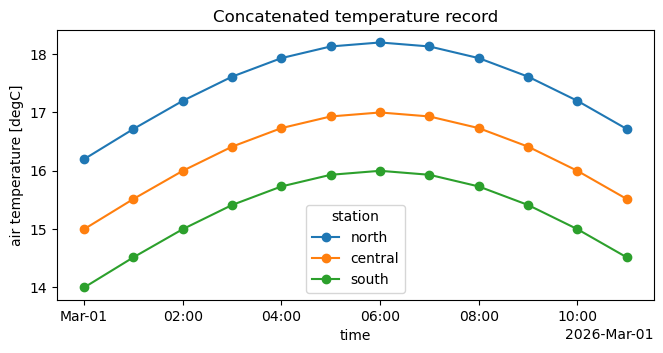

In [6]:
temperature.plot.line(
    x="time", hue="station", marker="o", size=3.5, aspect=2.2
)
plt.title("Concatenated temperature record")
plt.show()

Concatenation does not automatically decide how duplicate labels should be reconciled. An overlapping block can therefore create a non-unique time coordinate without raising an error.

In [7]:
overlapping_block = make_temperature_block(
    "2026-03-01T05:00",
    hour_offset=5,
    periods=3,
    station_offsets=primary_station_offsets,
    source="primary network",
)
with_overlap = xr.concat(
    [morning, overlapping_block], dim="time", join="exact"
)
duplicate_count = (
    with_overlap.sizes["time"]
    - np.unique(with_overlap["time"].values).size
)
print(f"duplicate time labels: {duplicate_count}")

duplicate time labels: 1


## Concatenate along a new dimension

Concatenation can also introduce a dimension. Here two scenarios have identical time and station coordinates, so the new `run` coordinate records which scenario produced each value.

In [8]:
baseline = temperature.assign_attrs(temperature.attrs | {"scenario": "baseline"})
warmer = (temperature + 0.8).assign_attrs(
    temperature.attrs | {"scenario": "warmer boundary condition"}
)
run = xr.DataArray(["baseline", "warmer"], dims="run", name="run")
ensemble = xr.concat(
    [baseline, warmer],
    dim=run,
    join="exact",
    combine_attrs="drop_conflicts",
)
ensemble

<xarray.DataArray 'temperature' (run: 2, time: 12, station: 3)> Size: 576B
16.2 15.0 14.0 16.72 15.52 14.52 17.2 ... 16.21 18.0 16.8 15.8 17.52 16.32 15.32
Coordinates:
  * run      (run) <U8 64B 'baseline' 'warmer'
  * time     (time) datetime64[ns] 96B 2026-03-01 ... 2026-03-01T11:00:00
  * station  (station) <U7 84B 'north' 'central' 'south'
Attributes: (3)

## Merge different variables

Pressure was measured at a partly different set of stations. Merging adds temperature and pressure as variables in one `Dataset`; the join policy determines its station coordinate.

In [9]:
pressure_station_offsets = {"central": 0.0, "south": 1.2, "east": -0.8}
pressure_hours = xr.DataArray(
    np.arange(temperature.sizes["time"], dtype=float),
    dims="time",
    coords={"time": temperature["time"]},
)
pressure_offset = xr.DataArray(
    list(pressure_station_offsets.values()),
    dims="station",
    coords={"station": list(pressure_station_offsets)},
)
pressure = (
    1013.0
    + 1.5 * np.cos(2.0 * np.pi * pressure_hours / 12.0)
    + pressure_offset
).transpose("time", "station").rename("pressure")
pressure.attrs = {"long_name": "air pressure", "units": "hPa"}

In [10]:
try:
    xr.merge(
        [temperature, pressure],
        join="exact",
        compat="no_conflicts",
        combine_attrs="drop_conflicts",
    )
except ValueError as error:
    print(f"{type(error).__name__}: {error}")

AlignmentError: cannot align objects with join='exact' where index/labels/sizes are not equal along these coordinates (dimensions): 'station' ('station',)


In [11]:
campaign = xr.merge(
    [temperature, pressure],
    join="outer",
    compat="no_conflicts",
    combine_attrs="drop_conflicts",
)
campaign

<xarray.Dataset> Size: 976B
Dimensions:      (time: 12, station: 4)
Coordinates:
  * time         (time) datetime64[ns] 96B 2026-03-01 ... 2026-03-01T11:00:00
  * station      (station) <U7 112B 'central' 'east' 'north' 'south'
Data variables:
    temperature  (time, station) float64 384B 15.0 nan 16.2 ... nan 16.72 14.52
    pressure     (time, station) float64 384B 1.014e+03 1.014e+03 ... 1.015e+03
Attributes: (1)

In [12]:
campaign.isnull().sum(dim=("time", "station"))

<xarray.Dataset> Size: 16B
Dimensions:      ()
Data variables:
    temperature  int64 8B 12
    pressure     int64 8B 12
Attributes: (1)

The outer join preserves every station label and represents unavailable combinations with `NaN`. Introducing missing values can change an integer variable to floating point, so dtype preservation must be checked when it matters.

## Detect conflicting values

Compatibility policies matter when two inputs contain the same named variable. An independent audit below disagrees with the reported temperature at one time. `compat="no_conflicts"` treats that disagreement as an error rather than silently choosing a value.

In [13]:
reported = temperature.sel(station="central").isel(time=slice(0, 4))
audited = reported.copy(deep=True)
audited[dict(time=2)] = audited.isel(time=2) + 0.5
try:
    xr.merge(
        [reported, audited],
        join="exact",
        compat="no_conflicts",
        combine_attrs="no_conflicts",
    )
except xr.MergeError as error:
    print(f"MergeError: {error}")

MergeError: conflicting values for variable 'temperature' on objects to be combined. You can skip this check by specifying compat='override'.


In [14]:
reported_first = xr.merge(
    [reported, audited],
    join="exact",
    compat="override",
    combine_attrs="override",
)["temperature"]
{
    "reported": float(reported.isel(time=2)),
    "audited": float(audited.isel(time=2)),
    "override result": float(reported_first.isel(time=2)),
}

{'reported': 16.0, 'audited': 16.5, 'override result': 16.0}

`compat="override"` makes input order part of the scientific result. Use it only when the first source is explicitly authoritative and retain independent evidence of any disagreement. Do not use it merely to suppress a merge failure.

## Fill gaps with a lower-priority source

The primary network has two missing central-station observations. A backup network overlaps two stations, adds an eastern station, and has a small calibration offset. One backup value also contains a deliberate fault for the later investigation.

In [15]:
primary = temperature.copy(deep=True)
primary[dict(time=[2, 7], station=1)] = np.nan

backup_station_offsets = {"central": 0.0, "south": -1.0, "east": 0.6}
backup = make_temperature_block(
    "2026-03-01T00:00",
    hour_offset=0,
    periods=12,
    station_offsets=backup_station_offsets,
    bias=0.05,
    source="backup network",
)
backup[dict(time=5, station=0)] = backup.isel(time=5, station=0) + 0.8

In [16]:
primary_first = primary.combine_first(backup)
backup_first = backup.combine_first(primary)
primary_first

<xarray.DataArray 'temperature' (time: 12, station: 4)> Size: 384B
15.0 15.65 16.2 14.0 15.52 16.17 16.72 ... 17.2 15.0 15.52 16.17 16.72 14.52
Coordinates:
  * time     (time) datetime64[ns] 96B 2026-03-01 ... 2026-03-01T11:00:00
  * station  (station) <U7 112B 'central' 'east' 'north' 'south'
Attributes: (3)

In [17]:
{
    "primary first": float(
        primary_first.isel(time=0).sel(station="central")
    ),
    "backup first": float(
        backup_first.isel(time=0).sel(station="central")
    ),
}

{'primary first': 15.0, 'backup first': 15.05}

`combine_first` uses the calling object wherever it has a value, fills its gaps from the other object, and returns the union of their coordinates. It is therefore deliberately not symmetric. The method encodes precedence but does not by itself record which source supplied each value.

## Optional: assemble many chunks by coordinates

`combine_by_coords` can order many chunks from their dimension coordinates. This is useful when filenames or input-list order do not express the scientific arrangement. It requires coordinates that determine one unambiguous monotonic result.

In [18]:
temperature_dataset = temperature.to_dataset()
chunks = [
    temperature_dataset.isel(time=slice(start, start + 3))
    for start in range(0, temperature.sizes["time"], 3)
]
shuffled_chunks = [chunks[2], chunks[0], chunks[3], chunks[1]]
reassembled = xr.combine_by_coords(
    shuffled_chunks,
    join="exact",
    compat="no_conflicts",
    combine_attrs="no_conflicts",
)
xr.testing.assert_identical(temperature_dataset, reassembled)
print("shuffled chunks were reassembled in coordinate order")

shuffled chunks were reassembled in coordinate order


## Investigation: combine without hiding disagreements

The campaign policy is:

- retain the union of primary and backup coordinates;
- use the primary value whenever it is available;
- use the backup only to fill a primary gap; and
- flag every overlapping observation that differs by more than $0.2\,{}^\circ\mathrm{C}$.

Choose and apply an appropriate combination operation. Construct a provenance array with values `primary`, `backup`, or `missing`, and a Boolean disagreement mask. Verify that the result contains a value wherever at least one source contains a value and that the primary source wins wherever it is available. The expected result contains exactly one flagged disagreement.

### Reference solution

In [19]:
primary_aligned, backup_aligned = xr.align(primary, backup, join="outer")
available = primary_aligned.notnull() | backup_aligned.notnull()
overlap = primary_aligned.notnull() & backup_aligned.notnull()
disagreement = (
    overlap & (abs(primary_aligned - backup_aligned) > 0.2)
).rename("disagreement")
provenance = xr.where(
    primary_aligned.notnull(),
    "primary",
    xr.where(backup_aligned.notnull(), "backup", "missing"),
).rename("provenance")
combined_temperature = primary.combine_first(backup)

In [20]:
xr.testing.assert_equal(combined_temperature.notnull(), available)
xr.testing.assert_equal(
    combined_temperature.where(primary_aligned.notnull()),
    primary_aligned,
)
assert int(disagreement.sum()) == 1
source_counts = {
    label: int((provenance == label).sum())
    for label in ("primary", "backup", "missing")
}
print(f"source counts: {source_counts}")
disagreement.where(disagreement, drop=True)

source counts: {'primary': 34, 'backup': 14, 'missing': 0}


<xarray.DataArray 'disagreement' (time: 1, station: 1)> Size: 8B
1.0
Coordinates:
  * time     (time) datetime64[ns] 8B 2026-03-01T05:00:00
  * station  (station) <U7 28B 'central'
Attributes: (2)

The scientific policy calls for `combine_first`, because it states a source priority rather than asserting that overlapping values agree. Alignment is performed separately to build quality-control and provenance variables over the same outer coordinate domain. Keeping those arrays prevents the convenience of gap filling from concealing a faulty backup observation.

## Recap

Before combining labeled data:

1. state whether inputs extend a dimension, add variables, or provide alternative values;
2. predict the intended coordinate set;
3. check monotonicity, uniqueness, gaps, and overlap;
4. set `join`, `compat`, attribute, and precedence policies explicitly;
5. verify coverage and conflicts after combination; and
6. retain provenance when source identity affects interpretation.

For multidimensional file layouts whose arrangement is known independently of their coordinates, consult `xr.combine_nested`. For many files on disk, `xr.open_mfdataset` uses the same combination concepts and introduces additional concerns about chunking, file handles, and lazy computation.